# Quiver Representations for Graph Analysis

**CIARP 2026 hands-on workshop** · Carlos Isaac Zainea Maya and Agustín Moreno Cañadas · Universidad Nacional de Colombia

This notebook follows the slides block by block. Every example is either a small hand-made quiver or a **simulated network** generated with a fixed seed, so nothing is downloaded and every number can be reproduced.

| Block in the slides | Section here | What you run |
|---|---|---|
| 01 · An applied process | [1](#1) | Reachability on a six-node network, with and without the bridge |
| 02 · Graphs become algebra | [2](#2) | Paths, the path algebra, relations and a representation of the diamond |
| 03 · The dynamic lens | [3](#3) | An impact automaton on a simulated network, and path-based multi-hop support |
| 04 · The structural lens | [4](#4) | Brauer configurations by hand, then on simulated citation corpora |
| Extension | [5](#5) | Optional: train GAT, a walk operator and Walk Attention on a synthetic task |

**Convention used everywhere:** paths are written left to right, so `ab` means first `a`, then `b`.

## 0. Setup

In [1]:
!pip install -q aiq-quivers

In [2]:
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import aiq
from aiq import Quiver, PathAlgebra, Ideal, QuotientAlgebra, AIQ, BrauerConfiguration

print("aiq-quivers", aiq.__version__)


def draw_quiver(Q, pos=None, title=None, colors=None, highlight=(), labels=True,
                node_size=900, figsize=(6, 4), seed=1):
    # Draw a quiver: parallel and opposite arrows are bent so that all of them are visible.
    G = nx.DiGraph()
    G.add_nodes_from(Q.Q0)
    G.add_edges_from((s, t) for _, s, t in Q.Q1)
    if pos is None:
        pos = nx.spring_layout(G, seed=seed)
    fig, ax = plt.subplots(figsize=figsize)
    node_colors = [(colors or {}).get(v, "white") for v in Q.Q0]
    nx.draw_networkx_nodes(G, pos, nodelist=list(Q.Q0), node_color=node_colors,
                           edgecolors="black", node_size=node_size, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)
    pairs = [(s, t) for _, s, t in Q.Q1]
    seen = {}
    for name, s, t in Q.Q1:
        k = seen.get((s, t), 0)
        seen[(s, t)] = k + 1
        bend = 0.0 if (k == 0 and (t, s) not in pairs) else 0.22 + 0.2 * k
        red = name in highlight
        nx.draw_networkx_edges(G, pos, edgelist=[(s, t)], ax=ax, node_size=node_size,
                               connectionstyle=f"arc3,rad={bend}", arrowsize=16,
                               edge_color="#E00234" if red else "#555555",
                               width=2.4 if red else 1.4)
        if labels and s != t:
            (x1, y1), (x2, y2) = pos[s], pos[t]
            ax.text((x1 + x2) / 2 + bend * (y2 - y1) / 2, (y1 + y2) / 2 - bend * (x2 - x1) / 2,
                    str(name), fontsize=10, style="italic", ha="center", va="center",
                    bbox=dict(fc="white", ec="none", pad=0.5))
    ax.set_title(title or "")
    ax.axis("off")
    plt.show()

aiq-quivers 1.2.1


<a id="1"></a>
## 1. An applied process

*Slides: "What changes when one link changes?" and "The picture is not the model".*

A signal spreads through a contact network. At each step an active node activates its outgoing neighbours, and an active node stays active. This is a deterministic teaching toy: there is no infection rate, no recovery and no calibration.

**Before running the cell, predict** which nodes will be reached from A. Then predict again without the bridge D → E.

t = 0: A
t = 1: A B C
t = 2: A B C D
t = 3: A B C D E
t = 4: A B C D E F


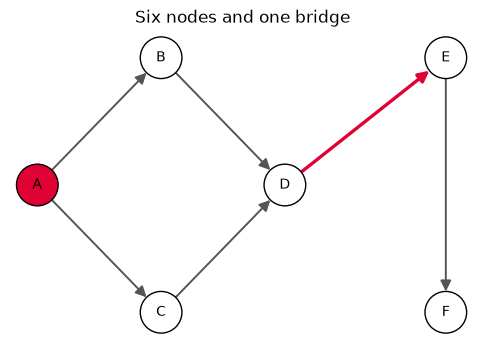

In [3]:
arrows = [("ab", "A", "B"), ("ac", "A", "C"), ("bd", "B", "D"),
          ("cd", "C", "D"), ("bridge", "D", "E"), ("ef", "E", "F")]
Q_toy = Quiver(list("ABCDEF"), arrows)
pos_toy = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0), "E": (3.3, 1), "F": (3.3, -1)}


def spread(Q, seeds, steps=6):
    # Deterministic, persistent activation along the arrows.
    active = set(seeds)
    history = [sorted(active)]
    for _ in range(steps):
        new = active | {t for _, s, t in Q.Q1 if s in active}
        if new == active:
            break
        active = new
        history.append(sorted(active))
    return history


for t, a in enumerate(spread(Q_toy, ["A"])):
    print(f"t = {t}: {' '.join(a)}")
draw_quiver(Q_toy, pos_toy, "Six nodes and one bridge", colors={"A": "#E00234"},
            highlight=["bridge"], labels=False)

In [4]:
Q_cut = Quiver(list("ABCDEF"), [a for a in arrows if a[0] != "bridge"])
for t, a in enumerate(spread(Q_cut, ["A"])):
    print(f"t = {t}: {' '.join(a)}")
print("\nNever reached without the bridge:",
      sorted(set("ABCDEF") - set(spread(Q_cut, ["A"])[-1])))

t = 0: A
t = 1: A B C
t = 2: A B C D

Never reached without the bridge: ['E', 'F']


**Discuss.** The picture did not change much, the outcome did. What did we have to specify to get an answer: the state of a node, what makes an interaction possible, what changes at each step, and which quantity we measure.

<a id="2"></a>
## 2. Graphs become algebra

*Slides: "A quiver makes direction explicit" to "A representation gives arrows something to do".*

A quiver is $Q = (Q_0, Q_1, s, t)$: vertices, arrows, and the source and target of each arrow. The **diamond** has two routes from A to D.

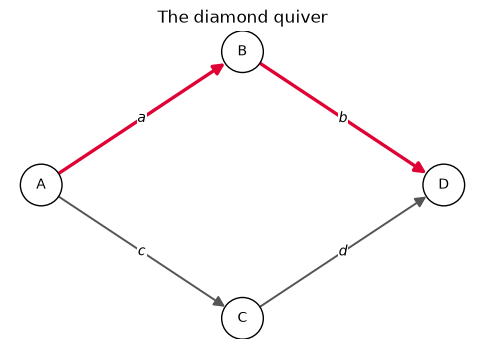

In [5]:
diamond = Quiver(list("ABCD"), [("a", "A", "B"), ("b", "B", "D"), ("c", "A", "C"), ("d", "C", "D")])
pos_d = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0)}
draw_quiver(diamond, pos_d, "The diamond quiver", highlight=["a", "b"])

### Exercise: list every basis path

Include the paths of length zero, one at each vertex. How many paths have length two? Can a path have length three? Answer on paper first, then run the cell.

In [6]:
kQ = PathAlgebra(diamond)
for length in range(4):
    paths = kQ.enumerate_paths(length)
    print(f"length {length}: {len(paths)} path(s)  ", [str(p) for p in paths])
print("\ndim KQ =", kQ.total_dimension())

length 0: 4 path(s)   ['e_A', 'e_B', 'e_C', 'e_D']
length 1: 4 path(s)   ['a', 'b', 'c', 'd']
length 2: 2 path(s)   ['a · b', 'c · d']
length 3: 0 path(s)   []

dim KQ = 10


### Paths are counted by powers of the adjacency matrix

The entry $(A^k)_{ij}$ is the number of paths of length $k$ from $i$ to $j$.

In [7]:
A = diamond.adjacency_matrix().astype(int)
print("A =\n", A)
print("\nA^2 =\n", A @ A)
print("\nPaths of length 2 from A to D:", [str(p) for p in kQ.paths_from_to("A", "D", 2)])

A =
 [[0 1 1 0]
 [0 0 0 1]
 [0 0 0 1]
 [0 0 0 0]]

A^2 =
 [[0 0 0 2]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

Paths of length 2 from A to D: ['a · b', 'c · d']


### Relations encode assumptions

A relation can identify two routes, or rule one out. The algebra is $KQ / I$, where the ideal $I$ contains the relations and their consequences. Change one relation at a time.

In [8]:
ab = kQ.path_element(["a", "b"])
cd = kQ.path_element(["c", "d"])

cases = {
    "none":    None,
    "ab = cd": Ideal(kQ, [ab - cd]),
    "ab = 0":  Ideal(kQ, [ab]),
}
rows = []
for name, ideal in cases.items():
    dim = kQ.total_dimension() if ideal is None else QuotientAlgebra(kQ, ideal).total_dimension()
    rows.append({"relation": name, "dim": dim})
pd.DataFrame(rows)

,relation,dim
0,none,10
1,ab = cd,9
2,ab = 0,9


### A representation

Put a vector space $V_i$ at each vertex and a linear map $f_a : V_i \to V_j$ on each arrow. A path acts by composing the maps, and a relation such as $ab = cd$ becomes the constraint $f_b f_a = f_d f_c$.

In [9]:
rng = np.random.default_rng(0)
f = {name: rng.integers(-2, 3, size=(2, 2)) for name in "abcd"}
print("Random maps satisfy ab = cd?", np.array_equal(f["b"] @ f["a"], f["d"] @ f["c"]))

# One way to satisfy the relation: make the two routes compose to the same map.
f["a"] = np.eye(2, dtype=int)
f["c"] = np.eye(2, dtype=int)
f["d"] = f["b"].copy()
print("After imposing the constraint?", np.array_equal(f["b"] @ f["a"], f["d"] @ f["c"]))

Random maps satisfy ab = cd? False
After imposing the constraint? True


<a id="3"></a>
## 3. The dynamic lens

*Slides: "Topology stays, state changes" to "Change one choice and explain the consequence".*

An impact automaton on a quiver is $\mathcal{A} = (Q, \Sigma, \{A_k\}, \varphi)$: the quiver, the set of states, the neighbourhoods by impact degree, and the update rule. The quiver says where influence can travel, the rule says how.

### A simulated network

Two communities of 15 nodes each, with random arrows inside each community and **one bridge** from the first to the second. The seed is fixed, so everyone gets the same network.

30 vertices, 67 arrows


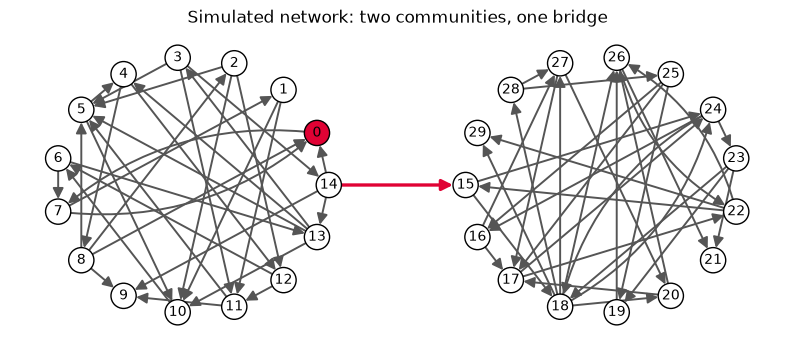

In [10]:
def simulated_network(n_per_community=15, p=0.16, bridge=True, seed=7):
    # Two random directed communities joined by a single bridge arrow.
    rng = np.random.default_rng(seed)
    n = n_per_community
    vertices = list(range(2 * n))
    arrows = []
    for block in (range(0, n), range(n, 2 * n)):
        for i in block:
            for j in block:
                if i != j and rng.random() < p:
                    arrows.append((f"e{i}_{j}", i, j))
    if bridge:
        arrows.append(("bridge", n - 1, n))
    return Quiver(vertices, arrows)


Q_sim = simulated_network()
Q_sim_cut = simulated_network(bridge=False)
print(Q_sim.n_vertices, "vertices,", Q_sim.n_arrows, "arrows")

# Each community on a circle; the bridge endpoints (14 and 15) face each other.
pos_sim = {}
for k in range(15):
    angle = 2 * math.pi * (k + 1) / 15
    pos_sim[k] = (math.cos(angle), math.sin(angle))
    pos_sim[29 - k] = (3.0 - math.cos(angle), math.sin(angle))
draw_quiver(Q_sim, pos_sim, "Simulated network: two communities, one bridge",
            colors={0: "#E00234"}, highlight=["bridge"], labels=False, node_size=330, figsize=(10, 4))

### Run the automaton

States: `S` (susceptible), `I` (active), `R` (removed). The rule is SIR: a susceptible node becomes active with a probability that depends on its active in-neighbours up to distance `g_max` (the rate is scaled by `beta` and clipped to [0, 1]), and an active node is removed with probability `recovery_prob`. Node 0 starts active.

`recovery_prob` is a parameter of this teaching simulator. Do not read it as a calibrated epidemiological rate.

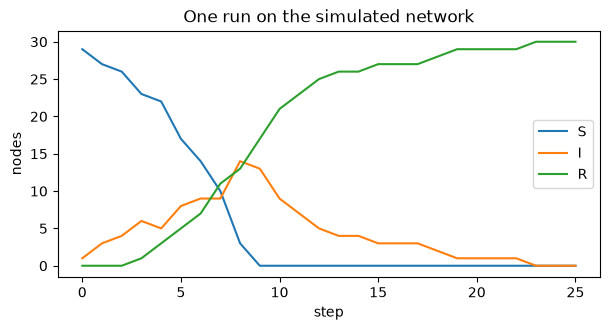

,S,I,R
t,,,
23,0,0,30
24,0,0,30
25,0,0,30


In [11]:
def run_automaton(Q, steps=25, seed=0, beta=3.0, recovery_prob=0.3, g_max=2):
    automaton = AIQ(Q, states=["S", "I", "R"], evolution_rule="SIR",
                    beta=beta, recovery_prob=recovery_prob, g_max=g_max)
    automaton.set_initial_config({v: ("I" if v == 0 else "S") for v in Q.Q0})
    automaton.run(steps, seed=seed)
    return automaton


run = run_automaton(Q_sim)
counts = run.orbit_counts_table().reindex(columns=["S", "I", "R"]).fillna(0).astype(int)
counts.plot(figsize=(7, 3.2), title="One run on the simulated network", xlabel="step", ylabel="nodes")
plt.show()
counts.tail(3)

### Does one arrow matter?

**Predict first:** how many nodes are ever reached with the bridge, and how many without it? One run is not evidence, so we repeat the simulation with 200 different random seeds.

      with bridge  without bridge
mean        27.93           14.13
std          7.13            3.16
min          1.00            1.00
max         30.00           15.00


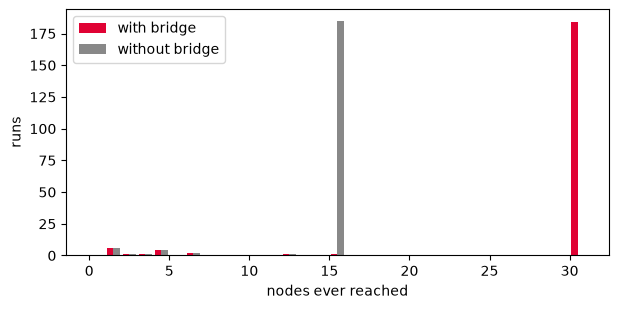

In [12]:
def ever_reached(Q, seed):
    final = run_automaton(Q, seed=seed).config
    return sum(state != "S" for state in final.values())


runs = 200
with_bridge = [ever_reached(Q_sim, s) for s in range(runs)]
without_bridge = [ever_reached(Q_sim_cut, s) for s in range(runs)]
summary = pd.DataFrame({"with bridge": with_bridge, "without bridge": without_bridge})
print(summary.describe().loc[["mean", "std", "min", "max"]].round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([with_bridge, without_bridge], bins=range(0, 32), label=["with bridge", "without bridge"],
        color=["#E00234", "#888888"])
ax.set_xlabel("nodes ever reached")
ax.set_ylabel("runs")
ax.legend()
plt.show()

### Let paths inform attention

Over-squashing: information from many distant nodes has to pass through few routes and is compressed into vectors of fixed size. Walk Attention uses the **support given by walks**: at range $g$, node $j$ may attend to node $i$ when there is a walk of length $g$ from $i$ to $j$, that is, when $(A^g)_{ij} \neq 0$.

Start with the five-node network of the slide and a hop budget.

In [13]:
small = Quiver(list("ABCDE"), [("ab", "A", "B"), ("ac", "A", "C"), ("bd", "B", "D"), ("be", "B", "E"),
                               ("cd", "C", "D"), ("ce", "C", "E"), ("de", "D", "E")])
A = small.adjacency_matrix().astype(int)
names = list(small.Q0)
reached, walks = set(), 0
for g in range(1, 4):
    Ag = np.linalg.matrix_power(A, g)
    row = Ag[names.index("A")]
    reached |= {names[j] for j in np.flatnonzero(row)}
    walks += int(row.sum())
    print(f"hop budget {g}: reach from A = {sorted(reached)},  walks so far = {walks}")

hop budget 1: reach from A = ['B', 'C'],  walks so far = 2
hop budget 2: reach from A = ['B', 'C', 'D', 'E'],  walks so far = 6
hop budget 3: reach from A = ['B', 'C', 'D', 'E'],  walks so far = 8


With three hops the reached nodes are the same as with two, but more walks contribute.

Now the same question on the simulated network: how many ordered pairs can exchange information at each range? This is the support that a path-based attention would use, compared with the full square that standard attention fills.

In [14]:
def support_table(Q, max_range=6):
    A = Q.adjacency_matrix().astype(float)
    n = Q.n_vertices
    rows, Ag = [], np.eye(n)
    for g in range(1, max_range + 1):
        Ag = Ag @ A
        pairs = int((Ag > 0).sum())
        rows.append({"range g": g, "pairs with a walk": pairs,
                     "% of all pairs": round(100 * pairs / n**2, 1),
                     "largest walk count": int(Ag.max())})
    return pd.DataFrame(rows).set_index("range g")


support_table(Q_sim)

,pairs with a walk,% of all pairs,largest walk count
range g,,,
1,67,7.4,1
2,132,14.7,2
3,226,25.1,4
4,331,36.8,8
5,402,44.7,14
6,450,50.0,36


### A bottleneck

$K$ sources feed $d$ layers of $M$ nodes, and everything ends in one target. The number of walks that arrive at the target grows like $K \cdot M^{d}$, while the target keeps a vector of fixed size.

In [15]:
def bottleneck(K=4, M=3, depth=2):
    layers = [[f"s{i}" for i in range(K)]]
    layers += [[f"h{l}_{i}" for i in range(M)] for l in range(depth)]
    layers += [["target"]]
    arrows = [(f"{u}>{v}", u, v) for a, b in zip(layers, layers[1:]) for u in a for v in b]
    return Quiver([v for layer in layers for v in layer], arrows)


for depth in (1, 2, 3, 4):
    Qb = bottleneck(depth=depth)
    Ab = Qb.adjacency_matrix().astype(int)
    arriving = int(np.linalg.matrix_power(Ab, depth + 1)[:, list(Qb.Q0).index("target")].sum())
    print(f"depth {depth}: {arriving:4d} walks arrive at the target   (K·M^d = {4 * 3**depth})")

depth 1:   12 walks arrive at the target   (K·M^d = 12)
depth 2:   36 walks arrive at the target   (K·M^d = 36)
depth 3:  108 walks arrive at the target   (K·M^d = 108)
depth 4:  324 walks arrive at the target   (K·M^d = 324)


### Hands-on: change one choice and explain the consequence

Keep the network and the measurement fixed. Change **one** structural choice, for example:

- the hop budget `max_range` in `support_table`,
- the bridge (`Q_sim` against `Q_sim_cut`),
- the density `p` in `simulated_network`,
- `g_max` or `recovery_prob` in `run_automaton`.

Write a four-line experiment log:

1. Our hypothesis
2. The single change we made
3. What we observed
4. What we still cannot conclude

In [16]:
# Your experiment. Example: the support without the bridge.
support_table(Q_sim_cut)

,pairs with a walk,% of all pairs,largest walk count
range g,,,
1,66,7.3,1
2,129,14.3,2
3,214,23.8,4
4,304,33.8,8
5,359,39.9,14
6,388,43.1,36


<a id="4"></a>
## 4. The structural lens: Brauer configurations

*Slides: "A configuration is not yet an algebra" to the simulated corpora.*

A Brauer configuration is $\Gamma = (\Gamma_0, \Gamma_1, \mu, \mathcal{O})$: vertices, polygons (multisets of vertices), a multiplicity for each vertex, and a cyclic order of the polygons around each vertex (Green and Schroll, 2017). Keep three levels apart: the configuration, its quiver, and the algebra $\Lambda = KQ/I$.

- $\mathrm{val}(\alpha)$: number of times $\alpha$ occurs in the polygons.
- $\alpha$ is truncated when $\mu(\alpha)\,\mathrm{val}(\alpha) = 1$.
- $\dim \Lambda = 2|\Gamma_1| + \sum_\alpha \mathrm{val}(\alpha)\,(\mu(\alpha)\,\mathrm{val}(\alpha) - 1)$.
- Masses $\mu(\alpha)\,\mathrm{val}(\alpha)$, total mass $\delta$, probabilities $p_\alpha = \mu(\alpha)\,\mathrm{val}(\alpha)/\delta$ and entropy $H = -\sum_\alpha p_\alpha \log_2 p_\alpha$ (Moreno Cañadas et al., 2024).

In [17]:
def report(bc, name=""):
    # The quantities used in the slides, for one Brauer configuration.
    r = bc.brauer_analysis()
    n = r["n_vertices"]
    return {"configuration": name, "polygons": r["n_polygons"], "vertices": n,
            "arrows": bc.brauer_quiver().n_arrows, "loops": r["n_loops"],
            "dim Λ": r["dimension"], "dim Z(Λ)": r["center_dimension"],
            "δ": int(r["impact_factor_delta_B"]), "H (bits)": round(r["entropy_H_B"], 4),
            "log2 |Γ0|": round(math.log2(n), 4)}


def successors(bc):
    for v, seq in bc.successor_sequences().items():
        polygons = [p for p, _ in seq]
        print(f"  {v}: val = {bc.valency(v)}, μ = {bc.mu(v)}, cycle "
              + " → ".join(map(str, polygons + polygons[:1])))

### 4.1 Two polygons, two shared vertices

Polygons $P$ and $Q$ both contain $\alpha$ and $\beta$, with $\mu = 1$. The vertex $\alpha$ gives the arrows $a : P \to Q$ and $b : Q \to P$; the vertex $\beta$ gives $c : P \to Q$ and $d : Q \to P$. By hand we found a basis with eight elements.

In [18]:
two = BrauerConfiguration(vertices=["alpha", "beta"],
                          polygons={"P": ["alpha", "beta"], "Q": ["alpha", "beta"]})
successors(two)
pd.DataFrame([report(two, "two polygons")])

  alpha: val = 2, μ = 1, cycle P → Q → P
  beta: val = 2, μ = 1, cycle P → Q → P


,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,two polygons,2,2,4,0,8,3,4,1.0,1.0


### 4.2 The published example with four polygons

$M_1 = \{m_1, m_2\}$, $M_2 = \{m_2, m_3\}$, $M_3 = \{m_3, m_4\}$, $M_4 = \{m_2, m_4\}$, with $\mu = (2, 1, 1, 1)$. Source: Moreno Cañadas et al., *Electron. Res. Arch.* 32(10), 2024.

**Exercise.** Compute the valencies by hand. Which vertices are truncated? Then check the published values $\dim \Lambda = 19$, $\dim Z(\Lambda) = 6$ and $H = 1.9749$.

In [19]:
published = BrauerConfiguration(
    vertices=["m1", "m2", "m3", "m4"],
    polygons={"M1": ["m1", "m2"], "M2": ["m2", "m3"], "M3": ["m3", "m4"], "M4": ["m2", "m4"]},
    mu={"m1": 2, "m2": 1, "m3": 1, "m4": 1})
successors(published)
print("truncated vertices:", [v for v in published.Gamma0 if published.is_truncated(v)])
pd.DataFrame([report(published, "published example")])

  m1: val = 1, μ = 2, cycle M1 → M1
  m2: val = 3, μ = 1, cycle M1 → M2 → M4 → M1
  m3: val = 2, μ = 1, cycle M2 → M3 → M2
  m4: val = 2, μ = 1, cycle M3 → M4 → M3
truncated vertices: []


,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,published example,4,4,8,1,19,6,9,1.9749,2.0


In [20]:
# The masses and the entropy, step by step.
masses = {v: published.mu(v) * published.valency(v) for v in published.Gamma0}
delta = sum(masses.values())
H = -sum(m / delta * math.log2(m / delta) for m in masses.values())
print("masses:", masses, " δ =", delta)
print(f"H = {H:.4f} bits, maximum log2(4) = {math.log2(4):.4f} bits")

masses: {'m1': 2, 'm2': 3, 'm3': 2, 'm4': 2}  δ = 9
H = 1.9749 bits, maximum log2(4) = 2.0000 bits


### 4.3 A corpus of articles as a configuration

| Datum | In a bibliography |
|---|---|
| $\Gamma_0$ | the references cited by at least one article |
| $\Gamma_1$ | the articles: each one is the polygon formed by its references |
| $\mu$ | 2 if the reference is cited once, 1 otherwise (the smallest choice with no truncated vertex) |
| $\mathcal{O}$ | chronological order of the citing articles |

**Exercise, by hand first.** Three articles in chronological order, five references:

$$P_1 = \{a, b, c\}, \qquad P_2 = \{b, c, d\}, \qquad P_3 = \{a, c, e\}$$

Find val and μ, the successor sequences, the number of arrows and loops, $\dim \Lambda$, $\dim Z(\Lambda)$, δ and $H$.

In [21]:
toy = BrauerConfiguration(
    vertices=["a", "b", "c", "d", "e"],
    polygons={"P1": ["a", "b", "c"],
              "P2": ["b", "c", "d"],
              "P3": ["a", "c", "e"]})

toy.brauer_analysis()

{'n_vertices': 5,
 'n_polygons': 3,
 'dimension': 18,
 'center_dimension': 6,
 'n_loops': 2,
 'defect': 0,
 'impact_factor_delta_B': 11,
 'entropy_H_B': 2.299896391167891,
 'valencies': {'a': 2, 'b': 2, 'c': 3, 'd': 1, 'e': 1},
 'multiplicities': {'a': 1, 'b': 1, 'c': 1, 'd': 2, 'e': 2},
 'truncated_vertices': [],
 'univalent_vertices': ['d', 'e'],
 'multivalent_vertices': ['a', 'b', 'c']}

  a: val = 2, μ = 1, cycle P1 → P3 → P1
  b: val = 2, μ = 1, cycle P1 → P2 → P1
  c: val = 3, μ = 1, cycle P1 → P2 → P3 → P1
  d: val = 1, μ = 2, cycle P2 → P2
  e: val = 1, μ = 2, cycle P3 → P3


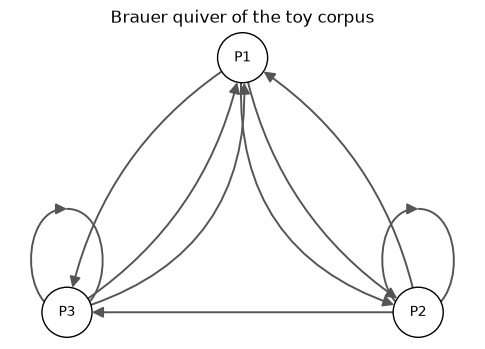

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,toy corpus,3,5,9,2,18,6,11,2.2999,2.3219


In [22]:
successors(toy)
draw_quiver(toy.brauer_quiver(), {"P1": (0, 1), "P2": (1.2, -0.6), "P3": (-1.2, -0.6)},
            "Brauer quiver of the toy corpus", labels=False, node_size=1300)
pd.DataFrame([report(toy, "toy corpus")])

**Now change one reference list and predict the new values before you run the cell.** For instance, what happens if $P_3$ also cites $b$?

In [23]:
toy2 = BrauerConfiguration(
    vertices=["a", "b", "c", "d", "e"],
    polygons={"P1": ["a", "b", "c"],
              "P2": ["b", "c", "d"],
              "P3": ["a", "b", "c", "e"]})   # edit this line
pd.DataFrame([report(toy, "toy corpus"), report(toy2, "edited")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,toy corpus,3,5,9,2,18,6,11,2.2999,2.3219
1,edited,3,5,10,2,22,6,12,2.2925,2.3219


### 4.4 Simulated corpora

We now build corpora instead of collecting them. Each new article chooses its references one by one: with probability `p_new` it cites a reference nobody has cited before, otherwise it cites an existing reference chosen in proportion to the citations that reference already has. Small `p_new` means that the corpus keeps returning to the same sources.

The data are simulated. The numbers describe the generator and its seed, and they are not a statement about any real author or field.

In [24]:
def simulate_corpus(n_articles=60, refs_per_article=12, p_new=0.5, seed=0):
    # A simulated corpus: article -> list of distinct references, in chronological order.
    rng = np.random.default_rng(seed)
    citations = []                # citations[r] = number of times reference r has been cited
    polygons = {}
    for k in range(n_articles):
        chosen = set()
        while len(chosen) < refs_per_article:
            free = [r for r in range(len(citations)) if r not in chosen]
            if not free or rng.random() < p_new:
                citations.append(0)
                r = len(citations) - 1
            else:
                weights = np.array([citations[x] for x in free], dtype=float)
                r = free[rng.choice(len(free), p=weights / weights.sum())]
            chosen.add(r)
        for r in chosen:
            citations[r] += 1
        polygons[f"P{k + 1:03d}"] = [f"r{r}" for r in sorted(chosen)]
    vertices = [f"r{r}" for r in range(len(citations))]
    years = {name: {"year": 2000 + i} for i, name in enumerate(polygons)}
    return BrauerConfiguration(vertices=vertices, polygons=polygons, polygon_data=years)


corpus = simulate_corpus(p_new=0.5, seed=0)
pd.DataFrame([report(corpus, "simulated, p_new = 0.5")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,"simulated, p_new = 0.5",60,333,720,218,3776,279,938,8.0524,8.3794


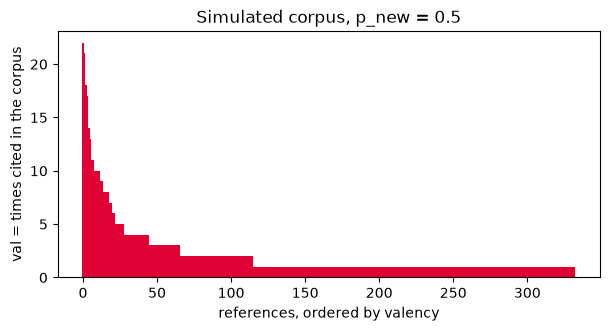

cited once: 218 of 333 references


In [25]:
valencies = sorted((corpus.valency(v) for v in corpus.Gamma0), reverse=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(valencies)), valencies, color="#E00234", width=1.0)
ax.set_xlabel("references, ordered by valency")
ax.set_ylabel("val = times cited in the corpus")
ax.set_title("Simulated corpus, p_new = 0.5")
plt.show()
print("cited once:", sum(v == 1 for v in valencies), "of", len(valencies), "references")

### One construction, several corpora

**Predict first:** as `p_new` goes down, what happens to the number of references, to $\dim \Lambda$ and to $H$ compared with its maximum $\log_2 |\Gamma_0|$?

In [26]:
rows = []
for p_new in (0.9, 0.7, 0.5, 0.3, 0.1, 0.02):
    r = report(simulate_corpus(p_new=p_new, seed=0), f"p_new = {p_new}")
    r["H / max"] = round(r["H (bits)"] / r["log2 |Γ0|"], 3)
    rows.append(r)
table = pd.DataFrame(rows).set_index("configuration").drop(columns=["arrows", "loops"])
table

,polygons,vertices,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|,H / max
configuration,,,,,,,,
p_new = 0.9,60,648,896,653,1312,9.3348,9.3399,0.999
p_new = 0.7,60,482,1534,429,1088,8.8320,8.9129,0.991
p_new = 0.5,60,333,3776,279,938,8.0524,8.3794,0.961
p_new = 0.3,60,220,6632,189,848,7.1985,7.7814,0.925
p_new = 0.1,60,74,20899,98,757,5.1762,6.2095,0.834
p_new = 0.02,60,31,34177,68,727,4.1241,4.9542,0.832


**Discuss.**

- Why does $\dim \Lambda$ grow when the corpus has fewer references?
- $H$ stays close to its maximum in most rows. What would a corpus with low $H$ look like? Try to build one by editing `simulate_corpus` or by writing the polygons yourself.
- Which of these readings are properties of the construction, and which would be claims about a research community?

In [27]:
# Your corpus. Example: every article cites the same core, plus one reference of its own.
core = [f"core{i}" for i in range(3)]
own = [f"own{k}" for k in range(20)]
star = BrauerConfiguration(vertices=core + own,
                           polygons={f"P{k + 1:02d}": core + [own[k]] for k in range(20)})
pd.DataFrame([report(star, "shared core + one own reference")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,shared core + one own reference,20,23,80,20,1200,41,100,3.6507,4.5236


<a id="5"></a>
## 5. Optional extension: train the three operators

*Slide: "Let paths inform attention". This part is not needed for the workshop exercises.*

Three models on one synthetic long-range retrieval task (a bottleneck with $K = 5$ sources, so chance is 0.20): **GAT** (one hop, learned weights), a **walk operator** (multi-hop, fixed weights) and **Walk Attention** (multi-hop, learned weights). It installs PyTorch Geometric and the `oversquash` package from the paper's repository, and takes about one or two minutes on CPU.

This is one small run with one seed. Read it as a demonstration, not as a replication of the results in the paper.

In [28]:
!pip install -q torch_geometric "git+https://github.com/Izainea/path-algebra-gnn"

In [29]:
# Train the three models on the bottleneck retrieval task (small, fast version).
import torch, torch.nn.functional as F, numpy as np, math
from torch.utils.data import DataLoader
from torch_geometric.loader import DataLoader as PyGLoader
from oversquash.data_bottleneck import make_bottleneck_graph
from oversquash.transforms import (AttachWalkMasks, collate_walk_masks,
                                   AttachWalkOperators, collate_walk_operators)
from oversquash.models import build_model
K, M, DEPTH = 5, 4, 3   # chance = 1/5 = 0.20
def ds(seed, n=1500):
    g = torch.Generator().manual_seed(seed)
    return [make_bottleneck_graph(K, M, DEPTH, g) for _ in range(n)]

def train_eval(m, tr, va, fwd, epochs=70, lr=2e-3, warmup=8):
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e+1)/warmup if e<warmup
                                            else 0.5*(1+math.cos(math.pi*(e-warmup)/max(1,epochs-warmup))))
    best = 0.0
    for e in range(epochs):
        m.train()
        for b in tr:
            opt.zero_grad(); lg,_ = fwd(m,b)
            F.cross_entropy(lg, b.y, ignore_index=-100).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        sch.step(); m.eval(); a=[]
        with torch.no_grad():
            for b in va:
                lg,_ = fwd(m,b); mm=b.root_mask
                a.append((lg[mm].argmax(-1)==b.y[mm]).float().mean().item())
        best = max(best, float(np.mean(a)))
    return best

def run(name, seed=0):
    torch.manual_seed(seed); data = ds(seed); nl = DEPTH+1
    if name=='gat':
        tr=PyGLoader(data[:1200],batch_size=128,shuffle=True); va=PyGLoader(data[1200:],batch_size=128)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None))
    elif name=='walkraw':
        tf=AttachWalkOperators(n_layers=nl); data=[tf(d) for d in data]
        tr=DataLoader(data[:1200],batch_size=128,shuffle=True,collate_fn=collate_walk_operators)
        va=DataLoader(data[1200:],batch_size=128,collate_fn=collate_walk_operators)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None),walk_raw=b.walk_raw)
    else:
        tf=AttachWalkMasks(n_layers=nl); data=[tf(d) for d in data]
        tr=DataLoader(data[:1200],batch_size=128,shuffle=True,collate_fn=collate_walk_masks)
        va=DataLoader(data[1200:],batch_size=128,collate_fn=collate_walk_masks)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None),walk_masks=b.walk_masks)
    m = build_model(name, data[0].x.size(-1), 16, data[0].num_classes, nl, heads=4)
    return train_eval(m, tr, va, fwd)

labels = {'gat': 'GAT (1 hop, learned weights)',
          'walkraw': 'Walk operator (multi-hop, fixed weights)',
          'walkattn': 'Walk Attention (multi-hop, learned weights)'}
for name, label in labels.items():
    print(f'{label:44s} accuracy = {run(name):.3f}')

GAT (1 hop, learned weights)                 accuracy = 0.208


Walk operator (multi-hop, fixed weights)     accuracy = 0.398


Walk Attention (multi-hop, learned weights)  accuracy = 1.000


## Two lenses, different questions

| Structural lens | Dynamic lens |
|---|---|
| Brauer configurations | Impact automata and Walk Attention |
| How can higher-order combinatorial data, cyclic order and multiplicity determine an algebra? | How can interactions evolve, and how can paths guide the exchange of information? |
| configuration → $KQ/I$ | paths → influence → update |

**Final activity.** In pairs, sketch a small applied problem: define the vertices and arrows, choose a structural or a dynamic question, give one path, one rule and one test, and state what would falsify your interpretation. No personal data.

---

Package: `pip install aiq-quivers` · Source: [github.com/Izainea/aiq-quivers](https://github.com/Izainea/aiq-quivers) and [github.com/Izainea/path-algebra-gnn](https://github.com/Izainea/path-algebra-gnn)

References: Green and Schroll, *Bull. Sci. Math.* 141 (2017) · Sierra, *J. Algebra* 510 (2018) · Moreno Cañadas et al., *Electron. Res. Arch.* 32(10) (2024) · Zainea Maya and Moreno Cañadas, CIARP 2026, LNCS, Springer.